# 02.1 — Results Deep-Dive: `gsadf_v1_period` Labeling Method

`02_model_training.ipynb` always reports the best (model, variant) combo per metal, which is fine for finding the ceiling — but it hides *which model* actually gets picked, and doesn't show what a single model looks at once it's fitted. This notebook looks specifically at the **GSADF V1-period** label variant (the one settled on for further use) and answers two questions:

1. **Which model gives the best evaluation score, per metal, for this labeling method?** (bar chart below)
2. **What does the single best-performing model actually learn?** (SHAP beeswarm plots, one per metal)

This notebook only reads the results already produced by `02_model_training.ipynb` (`outputs/all_results.csv`) and fits a small number of additional models purely to compute SHAP explanations — it does not re-run the 240-experiment grid.


In [1]:
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import shap

METALS       = {'Cobalt': 'CODALY', 'Copper': 'CUDALY', 'Lithium': 'LIDALY', 'Nickel': 'NIDALY'}
NEEDS_SCALE  = {'LASSO'}
SEED         = 42
LEVEL_NORM_WINDOW = 250

df_all_labels = pd.read_csv('../outputs/all_labels.csv')
df_all_labels['Date'] = pd.to_datetime(df_all_labels['Date'])
df_results = pd.read_csv('../outputs/all_results.csv')

print(f'Labels: {len(df_all_labels)} rows')
print(f'Results: {len(df_results)} rows from 02_model_training.ipynb')


Labels: 2152 rows
Results: 240 rows from 02_model_training.ipynb


In [2]:
# ── Same helpers as 02_model_training.ipynb (kept identical for consistency) ─

def prepare_features(target_metal, label_variant, df_master):
    """Create the lagged feature matrix for one (metal, label variant). No look-ahead."""
    target_col = f'{target_metal}_{label_variant}'
    price_cols = list(METALS.values())
    macro_cols = [c for c in df_master.columns
                  if c not in ['Date'] + price_cols
                  and not any(c.startswith(m + '_') for m in METALS)]
    num_cols = price_cols + macro_cols

    out = pd.DataFrame({'Date': df_master['Date']})
    for col in num_cols:
        s = df_master[col]
        if (s <= 0).any():
            ret = s.diff()
            rel = s - s.rolling(LEVEL_NORM_WINDOW, min_periods=60).mean()
        else:
            ret  = np.log(s).diff()
            roll = s.rolling(LEVEL_NORM_WINDOW, min_periods=60).mean()
            rel  = np.log(s / roll)
        out[col + '_Ret_L1']      = ret.shift(1)
        out[col + '_Vol10_L1']    = ret.rolling(10).std().shift(1)
        out[col + '_RelLevel_L1'] = rel.shift(1)

    out['Target'] = df_master[target_col].astype(int)
    return out.dropna().reset_index(drop=True)


def build_model(mname, params=None):
    p = dict(params) if params else {}
    if mname == 'LASSO':
        return LogisticRegression(penalty='l1', solver='saga',
                                   C=0.1, max_iter=10000, random_state=SEED, **p)
    if mname == 'RF':
        return RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=3,
                                      max_features='sqrt', random_state=SEED, **p)
    if mname == 'XGBoost':
        return xgb.XGBClassifier(max_depth=3, learning_rate=0.05, n_estimators=300,
                                 min_child_weight=2, reg_alpha=0.5, reg_lambda=2.0,
                                 subsample=0.8, colsample_bytree=0.8,
                                 eval_metric='auc', verbosity=0, random_state=SEED, **p)
    if mname == 'LightGBM':
        return lgb.LGBMClassifier(max_depth=3, learning_rate=0.05, n_estimators=300,
                                  min_child_samples=5, reg_alpha=0.5, reg_lambda=2.0,
                                  subsample=0.8, colsample_bytree=0.8,
                                  verbose=-1, random_state=SEED, **p)
    if mname == 'CatBoost':
        return CatBoostClassifier(depth=3, learning_rate=0.05, iterations=300,
                                  l2_leaf_reg=3.0, subsample=0.8,
                                  verbose=0, random_state=SEED, **p)
    raise ValueError(f'Unknown model: {mname}')


# ── Human-readable feature labels (same mapping as 02_model_training.ipynb) ─
TICKER_NAMES = {
    'CODALY': 'Cobalt spot price', 'CUDALY': 'Copper spot price',
    'LIDALY': 'Lithium spot price', 'NIDALY': 'Nickel spot price',
    'OIL_WTI': 'WTI Crude Oil', 'GAS_HHUB': 'Natural Gas (Henry Hub)',
    'USD_INDEX': 'US Dollar Index (DXY)', 'VIX': 'VIX Fear Index',
    'YIELD_10Y': '10-Year Treasury Yield', 'GOLD_FUT': 'Gold Futures',
    'MSCI_ETF': 'MSCI World Equity ETF', 'MSCI_EM': 'MSCI Emerging Markets',
    'SP500': 'S&P 500', 'QCLN': 'Clean Energy ETF (QCLN)',
    'C_CHR': 'China Coal Energy (HK)', 'C_US': 'US Coal (BTU)',
}
TRANSFORM_LABELS = {
    '_Ret_L1':      '→ daily return',
    '_Vol10_L1':    '→ 10-day volatility',
    '_RelLevel_L1': '→ level vs 1-yr average',
}

def make_readable_label(raw):
    for sfx, label in TRANSFORM_LABELS.items():
        if raw.endswith(sfx):
            return f'{TICKER_NAMES.get(raw[:-len(sfx)], raw[:-len(sfx)])}  {label}'
    return raw


def filter_nonzero_shap(sv_expl, min_mean_abs=1e-6):
    mean_abs = np.abs(sv_expl.values).mean(axis=0)
    keep = mean_abs > min_mean_abs
    filtered = shap.Explanation(
        values=sv_expl.values[:, keep], base_values=sv_expl.base_values,
        data=sv_expl.data[:, keep],
        feature_names=[n for n, k in zip(sv_expl.feature_names, keep) if k])
    return filtered, int((~keep).sum())


def compute_and_save_shap(metal, variant, mname, df, suffix=''):
    """Fit model, compute SHAP on last ~20% of the series, save beeswarm plot."""
    df_ml  = prepare_features(metal, variant, df)
    feats  = [c for c in df_ml.columns if c not in ['Date', 'Target']]
    X_all  = df_ml[feats].values
    y_all  = df_ml['Target'].values

    n_test = max(100, len(X_all) // 5)
    X_tr, X_te = X_all[:-n_test], X_all[-n_test:]
    y_tr        = y_all[:-n_test]

    if mname in NEEDS_SCALE:
        sc   = StandardScaler()
        X_tr = sc.fit_transform(X_tr)
        X_te = sc.transform(X_te)

    model = build_model(mname)
    model.fit(X_tr, y_tr)

    explainer = shap.LinearExplainer(model, X_tr) if mname in NEEDS_SCALE else shap.TreeExplainer(model)
    sv   = explainer(X_te)
    vals = sv.values
    if vals.ndim == 3:
        vals = vals[:, :, 1]
        base = sv.base_values[:, 1] if sv.base_values.ndim == 2 else sv.base_values
    else:
        base = sv.base_values if sv.base_values.ndim == 1 else sv.base_values[:, 0]

    readable_names = [make_readable_label(f) for f in feats]
    sv_plot = shap.Explanation(values=vals, base_values=base, data=X_te, feature_names=readable_names)
    sv_plot, n_dropped = filter_nonzero_shap(sv_plot)
    max_disp = min(15, sv_plot.values.shape[1])

    with plt.rc_context({'font.size': 12, 'axes.labelsize': 12, 'xtick.labelsize': 11,
                         'ytick.labelsize': 12, 'axes.titlesize': 13}):
        shap.plots.beeswarm(sv_plot, max_display=max_disp, show=False)
        fig = plt.gcf()
        fig.set_size_inches(14, 9)
        fig.subplots_adjust(top=0.88)
        fig.suptitle(f'{metal}  —  Top drivers of bubble predictions  [{mname}]',
                    fontsize=15, fontweight='bold', y=0.97)
        note = f'  ({n_dropped} zero-weight features hidden)' if n_dropped > 0 else ''
        fig.text(0.5, 0.91,
                 f'Model: {mname}  ·  Label: {variant}  ·  SHAP on last ~20 % of data (no look-ahead){note}',
                 ha='center', va='top', fontsize=10, color='#555555', transform=fig.transFigure)
        fname = f'../outputs/shap_{metal.lower()}_{mname.lower()}{suffix}.png'
        plt.savefig(fname, dpi=150, bbox_inches='tight', facecolor='white')
        plt.show()
        print(f'  Saved → {fname}')

    mean_abs = np.abs(sv_plot.values).mean(axis=0)
    top_idx  = int(np.argmax(mean_abs))
    print(f'    active features: {sv_plot.values.shape[1]:2d}  (dropped {n_dropped} zeros)  '
          f'top: {sv_plot.feature_names[top_idx]}  (mean|SHAP|={mean_abs[top_idx]:.4f})')

print('Helpers ready.')


Helpers ready.


## 1. Which model gives the best score, per metal, for `gsadf_v1_period`?

All 5 models were already evaluated on this label variant in `02_model_training.ipynb`; the bars below just make the comparison visible instead of only reporting the single winning row per metal.


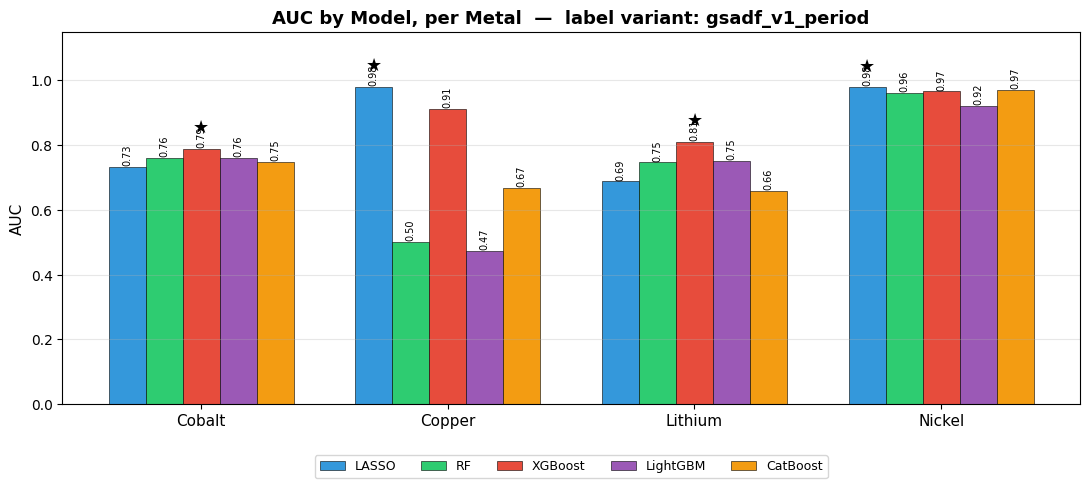

Winning model per metal for gsadf_v1_period (by AUC):
  Cobalt   → XGBoost   AUC=0.788
  Copper   → LASSO     AUC=0.981
  Lithium  → XGBoost   AUC=0.811
  Nickel   → LASSO     AUC=0.979

Mean AUC across all 4 metals, per model (this label variant only):
Model
XGBoost     0.869
LASSO       0.845
CatBoost    0.762
RF          0.743
LightGBM    0.727

→ Using "XGBoost" for the SHAP plots below — highest average AUC across all 4 metals for gsadf_v1_period, even though it is not the single best model on every metal individually.


In [3]:
VARIANT      = 'gsadf_v1_period'
MODEL_ORDER  = ['LASSO', 'RF', 'XGBoost', 'LightGBM', 'CatBoost']
palette      = {'LASSO': '#3498db', 'RF': '#2ecc71', 'XGBoost': '#e74c3c',
                'LightGBM': '#9b59b6', 'CatBoost': '#f39c12'}

sub = df_results[(df_results.Variant == VARIANT) & df_results.AUC.notna()].copy()
pivot_auc = sub.pivot_table(index='Metal', columns='Model', values='AUC').reindex(
    index=list(METALS), columns=MODEL_ORDER)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(pivot_auc.index))
width = 0.15
for i, mname in enumerate(MODEL_ORDER):
    vals = pivot_auc[mname].values
    bars = ax.bar(x + (i - 2) * width, vals, width, label=mname,
                  color=palette[mname], edgecolor='black', lw=0.4)
    for bar, val in zip(bars, vals):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f'{val:.2f}',
                    ha='center', fontsize=7, rotation=90)

# Mark the winning model per metal with a star above its bar
for xi, metal in zip(x, pivot_auc.index):
    row = pivot_auc.loc[metal]
    best_m = row.idxmax()
    best_i = MODEL_ORDER.index(best_m)
    ax.text(xi + (best_i - 2) * width, row.max() + 0.05, '★', ha='center', fontsize=13, color='black')

ax.set_xticks(x)
ax.set_xticklabels(pivot_auc.index, fontsize=11)
ax.set_ylabel('AUC', fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title(f'AUC by Model, per Metal  —  label variant: {VARIANT}', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/02.1_model_per_metal_auc.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f'Winning model per metal for {VARIANT} (by AUC):')
for metal in METALS:
    row = pivot_auc.loc[metal]
    print(f'  {metal:8s} → {row.idxmax():8s}  AUC={row.max():.3f}')

mean_auc = pivot_auc.mean(axis=0).sort_values(ascending=False)
print(f'\nMean AUC across all 4 metals, per model (this label variant only):')
print(mean_auc.round(3).to_string())
BEST_MODEL = mean_auc.idxmax()
print(f'\n→ Using "{BEST_MODEL}" for the SHAP plots below — highest average AUC '
      f'across all 4 metals for {VARIANT}, even though it is not the single best model on every metal individually.')


## 2. SHAP — `gsadf_v1_period`, one model, all 4 metals

Same style as Section 4 of `02_model_training.ipynb`, but using a single model (chosen above) applied consistently across all four metals for this one label variant, so the four plots are directly comparable to each other. SHAP computed on the last ~20% of each metal's series (chronological hold-out, no look-ahead).


Computing SHAP: XGBoost on gsadf_v1_period × 4 metals ...



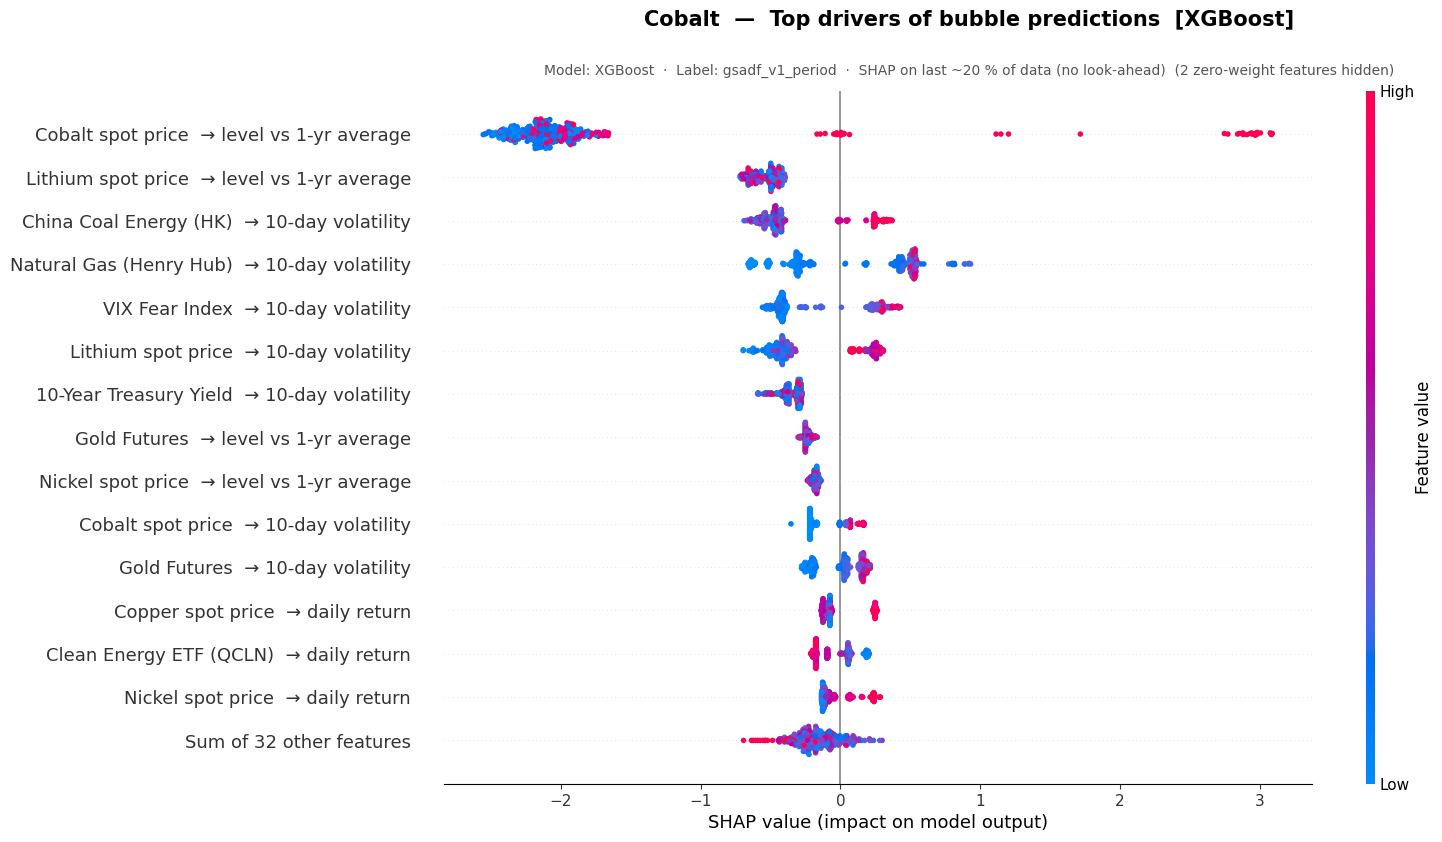

  Saved → ../outputs/shap_cobalt_xgboost_gsadf_v1_period.png
    active features: 46  (dropped 2 zeros)  top: Cobalt spot price  → level vs 1-yr average  (mean|SHAP|=2.0803)


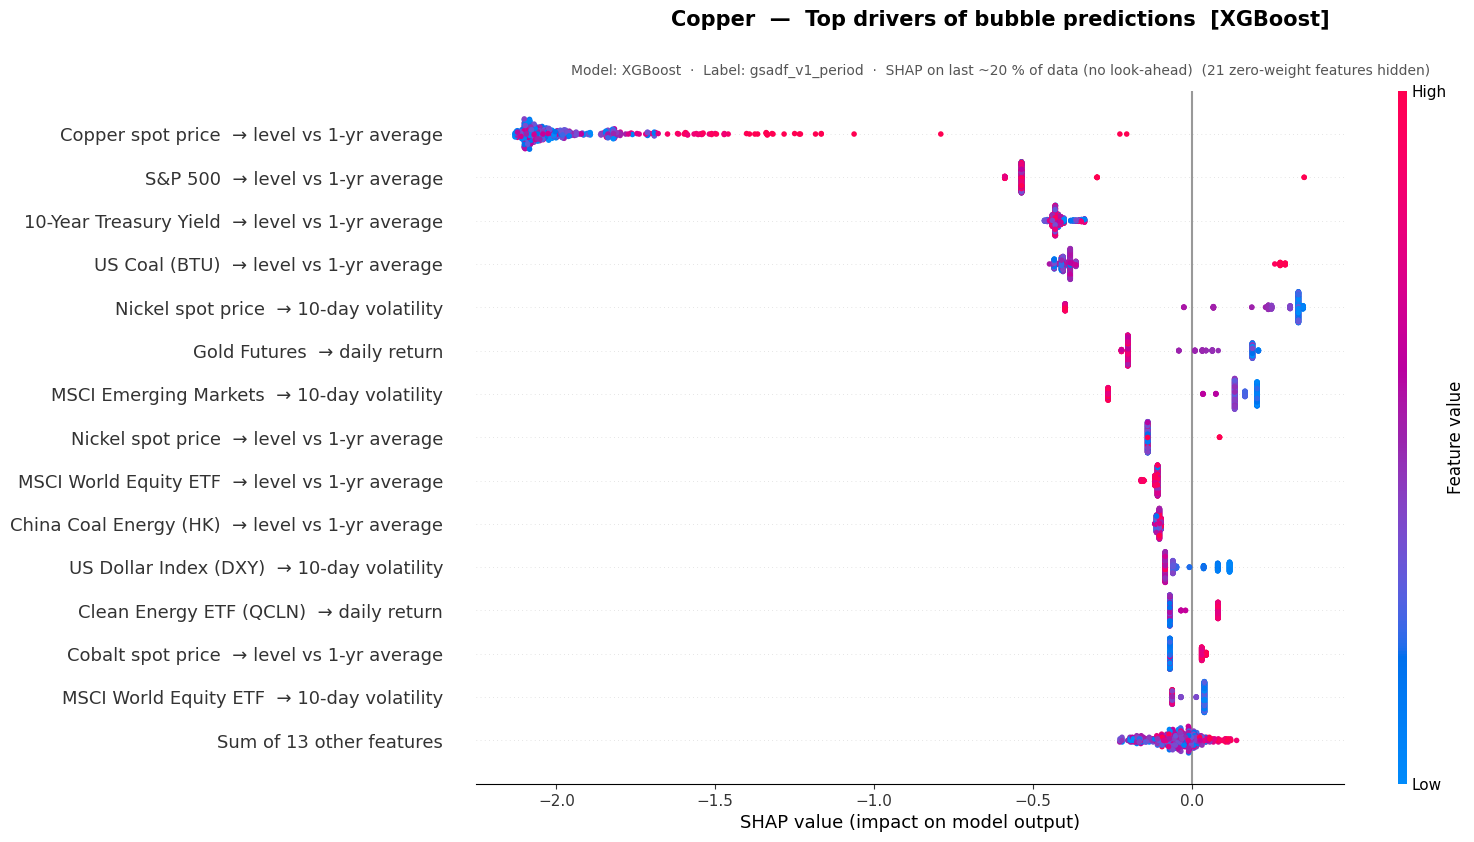

  Saved → ../outputs/shap_copper_xgboost_gsadf_v1_period.png
    active features: 27  (dropped 21 zeros)  top: Copper spot price  → level vs 1-yr average  (mean|SHAP|=1.9210)


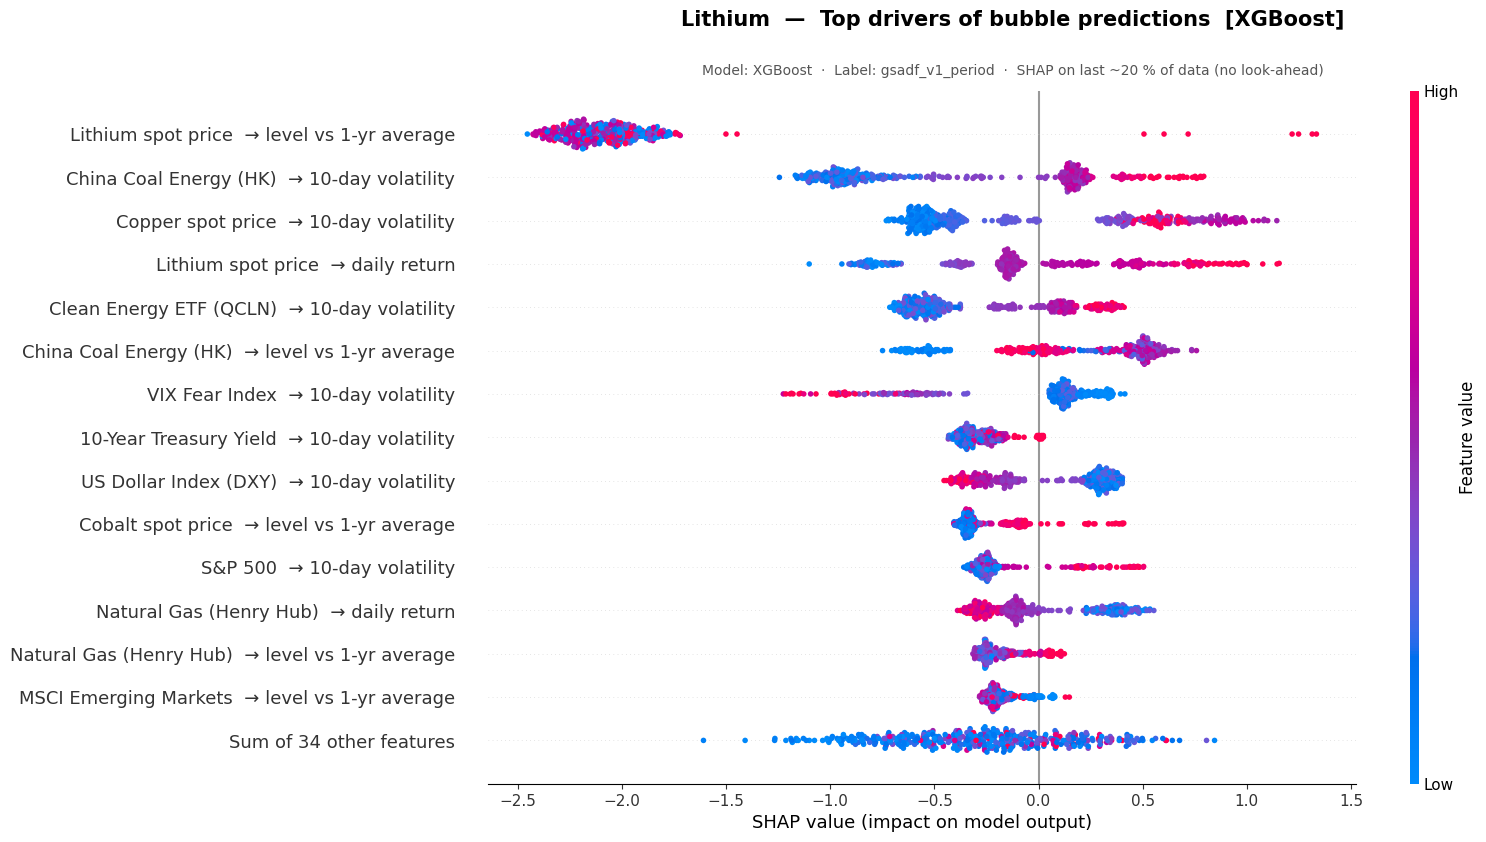

  Saved → ../outputs/shap_lithium_xgboost_gsadf_v1_period.png
    active features: 48  (dropped 0 zeros)  top: Lithium spot price  → level vs 1-yr average  (mean|SHAP|=2.0810)


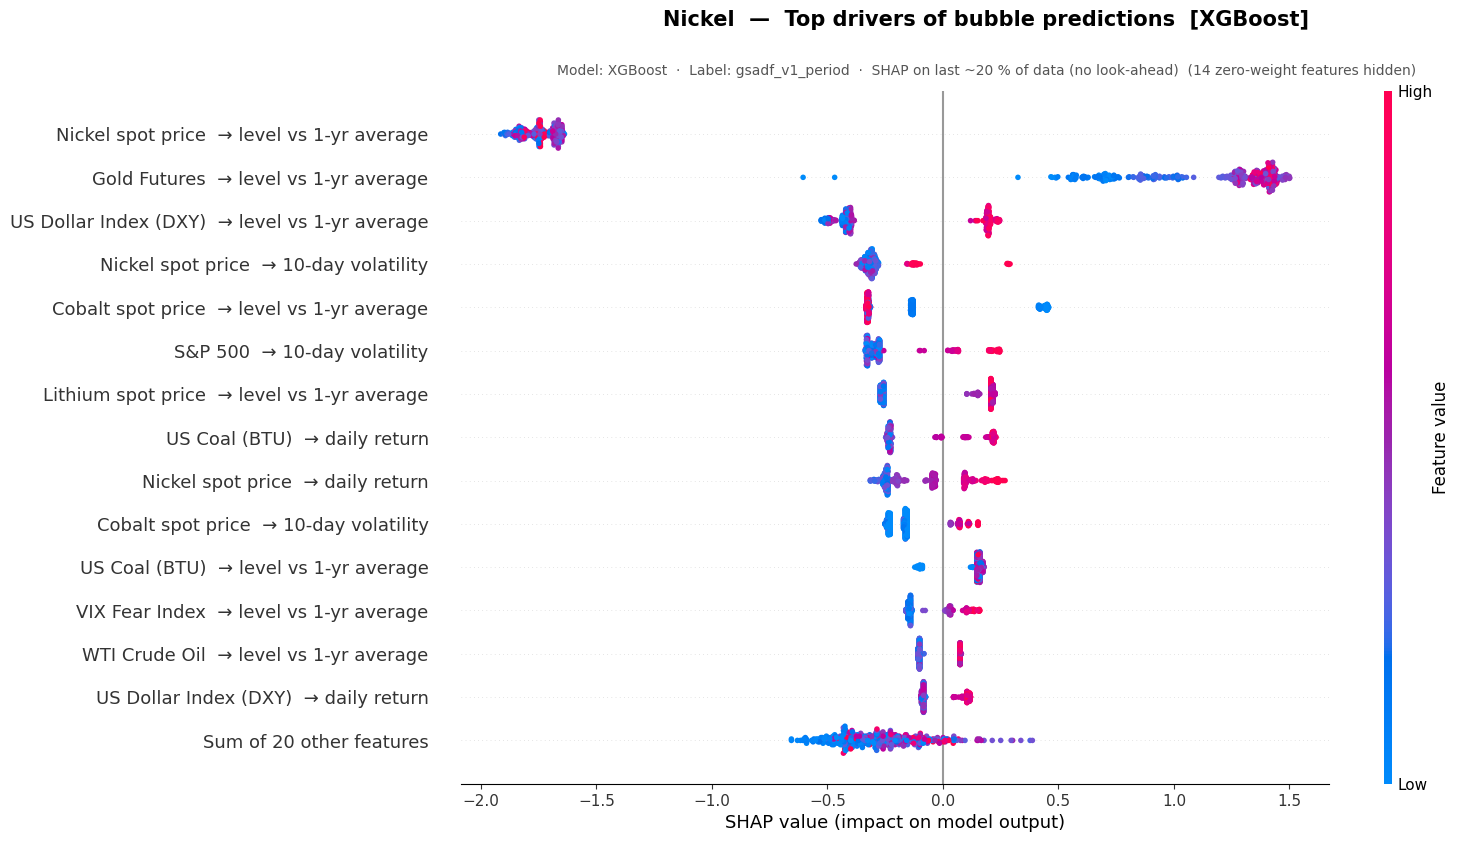

  Saved → ../outputs/shap_nickel_xgboost_gsadf_v1_period.png
    active features: 34  (dropped 14 zeros)  top: Nickel spot price  → level vs 1-yr average  (mean|SHAP|=1.7449)

Done. Saved outputs/shap_<metal>_xgboost_gsadf_v1_period.png


In [4]:
print(f'Computing SHAP: {BEST_MODEL} on {VARIANT} × 4 metals ...\n')

for metal in METALS:
    label_col = f'{metal}_{VARIANT}'
    if label_col not in df_all_labels.columns or int(df_all_labels[label_col].sum()) < 10:
        print(f'  {metal}: too few positive days — skipping')
        continue
    compute_and_save_shap(metal=metal, variant=VARIANT, mname=BEST_MODEL,
                          df=df_all_labels, suffix=f'_{VARIANT}')

print(f'\nDone. Saved outputs/shap_<metal>_{BEST_MODEL.lower()}_{VARIANT}.png')
